# Data Analysis & Visualization (DAV) — Lab 2
## Topic: Visual Encodings, Chart Types, Outlier Detection, and Graphical Integrity
---
- **Dataset:** Adult Census Income (`adult.csv`)
- **Roll Number:** `24i-2514`
- **Section:** `DS-5B`
---

### Step 0: Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset
df = pd.read_csv('adult.csv')

# Standardize column names (replace '.' with '-')
df.columns = df.columns.str.replace('.', '-', regex=False).str.strip()

# Strip whitespace from categorical columns
for col in df.select_dtypes('object').columns:
    df[col] = df[col].astype(str).str.strip()

# Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


---
## Task 1 : Bar Chart: Compare a Category
> **Prompt:** Create a bar chart comparing a numeric column's average across a categorical column (e.g., average hours-per-week by occupation). Label your axes and title the chart.

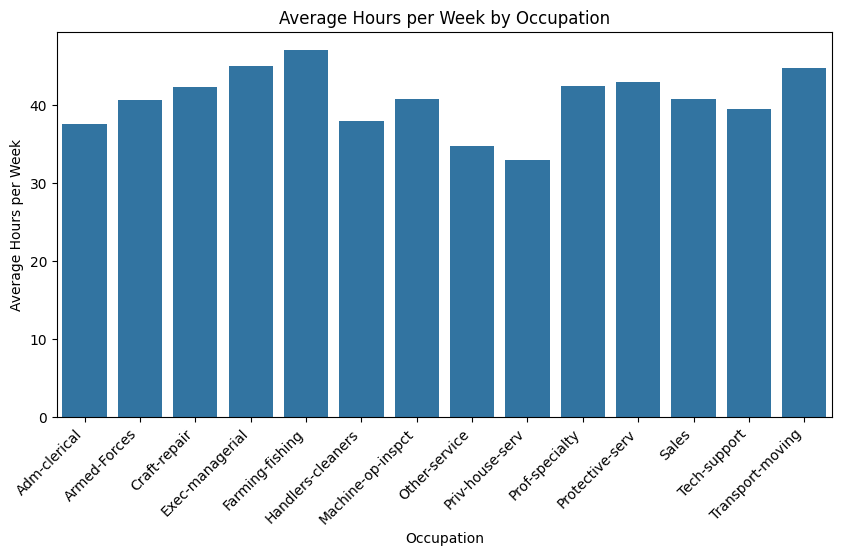

           occupation  hours-per-week
0        Adm-clerical       37.558355
1        Armed-Forces       40.666667
2        Craft-repair       42.304221
3     Exec-managerial       44.987703
4     Farming-fishing       46.989940
5   Handlers-cleaners       37.947445
6   Machine-op-inspct       40.755744
7       Other-service       34.701669
8     Priv-house-serv       32.885906
9      Prof-specialty       42.386715
10    Protective-serv       42.870570
11              Sales       40.781096
12       Tech-support       39.432112
13   Transport-moving       44.656230


In [2]:
# Task 1: Bar chart of average hours-per-week by occupation
avg_hours = df.groupby('occupation')['hours-per-week'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=avg_hours, x='occupation', y='hours-per-week')
plt.title('Average Hours per Week by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Average Hours per Week')
plt.xticks(rotation=45, ha='right')
plt.ylim(bottom=0)
plt.show()

# Display the values
print(avg_hours)

**Explanation:**
- The bar chart compares the average `hours-per-week` across different `occupation` categories.
- Bars use length and position starting from zero baseline ($y=0$) to show honest comparisons.
- `Farming-fishing` and `Exec-managerial` show the highest average hours worked per week, while `Priv-house-serv` has the lowest.

---
## Task 2 : Count Plot: Category Frequency
> **Prompt:** Create a count plot showing how many records fall into each category of one categorical column. Which category is most common?

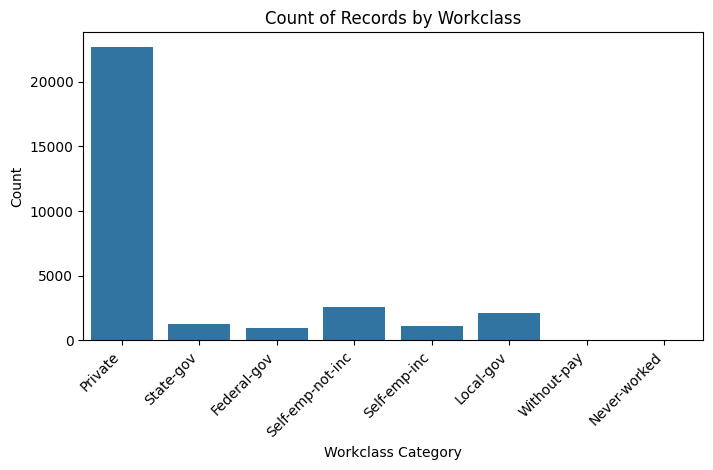

Value counts for workclass:
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
NaN                  1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64


In [3]:
# Task 2: Count plot for workclass
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='workclass')
plt.title('Count of Records by Workclass')
plt.xlabel('Workclass Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.show()

# Find the most common category
print("Value counts for workclass:")
print(df['workclass'].value_counts(dropna=False))

**Answer to Question:**
- **Which category is most common?**
  - The **`Private`** workclass is by far the most common category with **22,696 records** (approx. 70% of the dataset).

---
## Task 3 : Histogram: Distribution Shape
> **Prompt:** Create a histogram of one numeric column. Describe its shape in one sentence — is it symmetric, skewed left, or skewed right?

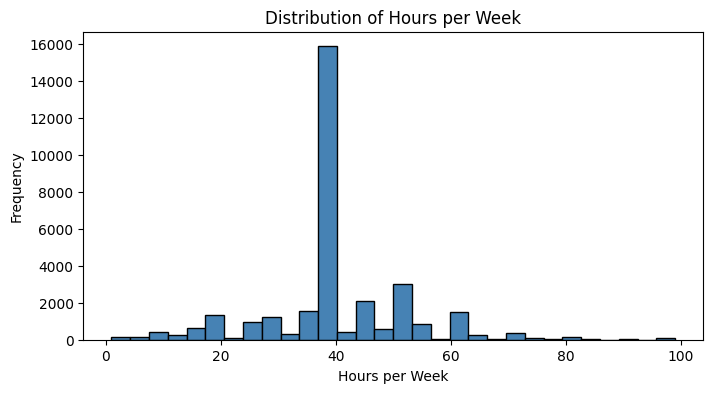

Mean: 40.437455852092995
Median: 40.0
Skewness: 0.227642536804501


In [4]:
# Task 3: Histogram of hours-per-week
plt.figure(figsize=(8, 4))
plt.hist(df['hours-per-week'], bins=30, edgecolor='black', color='steelblue')
plt.title('Distribution of Hours per Week')
plt.xlabel('Hours per Week')
plt.ylabel('Frequency')
plt.show()

print("Mean:", df['hours-per-week'].mean())
print("Median:", df['hours-per-week'].median())
print("Skewness:", df['hours-per-week'].skew())

**One-Sentence Shape Description:**
> **"The distribution of `hours-per-week` is slightly right-skewed (skewness $\approx +0.23$) with an extreme spike/mode at exactly 40 hours per week representing the standard full-time workweek."**

---
## Task 4 : Box Plot: Visual Outlier Detection
> **Prompt:** Create a box plot of the same numeric column from Task 3, optionally split by a category. Identify how many outlier points (if any) appear beyond the whiskers, just by looking.

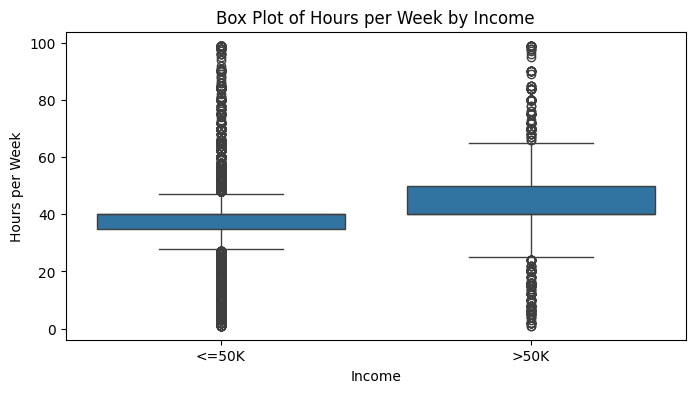

In [5]:
# Task 4: Box plot for hours-per-week, split by income
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='income', y='hours-per-week')
plt.title('Box Plot of Hours per Week by Income')
plt.xlabel('Income')
plt.ylabel('Hours per Week')
plt.show()

**Visual Outlier Observations:**
- **Just by looking at the box plot:**
  - The box represents the IQR ($Q_1$ to $Q_3$), located tightly between 40 and 45.
  - There are numerous individual outlier dots extending **below the lower whisker** (part-time work from 1 to 30 hours).
  - There are also many outlier dots extending **above the upper whisker** (overtime work from 55 to 99 hours).
  - Visually, there appear to be **thousands of outlier points** scattered beyond both whiskers, but exact counts cannot be determined visually because dots overlap heavily (*overplotting*).

---
## Task 5 : Outlier Detection: The Mechanism (IQR)
> **Prompt:** Using the same column from Task 4, calculate the IQR bounds manually:
> ```python
> Q1 = df['col'].quantile(0.25)
> Q3 = df['col'].quantile(0.75)
> IQR = Q3 - Q1
> lower = Q1 - 1.5 * IQR
> upper = Q3 + 1.5 * IQR
> outliers = df[(df['col'] < lower) | (df['col'] > upper)]
> print(len(outliers))
> ```
> *Compare this count to what you visually counted in Task 4 — do they match?*

In [6]:
# Task 5: Exact manual IQR calculation as given in the manual
Q1 = df['hours-per-week'].quantile(0.25)
Q3 = df['hours-per-week'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['hours-per-week'] < lower) | (df['hours-per-week'] > upper)]

print("Q1 (25%):", Q1)
print("Q3 (75%):", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of IQR outliers:", len(outliers))

Q1 (25%): 40.0
Q3 (75%): 45.0
IQR: 5.0
Lower bound: 32.5
Upper bound: 52.5
Number of IQR outliers: 9008


**Comparison with Task 4 Visual Count:**
- **Do they match?**
  - Yes, conceptually they match because the box plot's whiskers are drawn using these exact lower ($32.5$) and upper ($52.5$) bounds.
  - However, the mathematical calculation reveals that there are **9,008 outliers** (~27.7% of the dataset), which is much higher than what looks like just a few dozen points on the box plot because thousands of data points share the exact same integer coordinates (e.g. 20, 50, 60 hours).

---
## Task 6 : Outlier Detection: Z-score Comparison
> **Prompt:** Run the z-score method on the same column:
> ```python
> from scipy import stats
> df['zscore'] = stats.zscore(df['col'])
> outliers_z = df[df['zscore'].abs() > 3]
> print(len(outliers_z))
> ```
> *Do IQR and z-score flag the same number of outliers? If not, explain why, referencing whether your column's distribution is symmetric or skewed (from Task 3).*

In [7]:
# Task 6: Z-score calculation as given in the manual
from scipy import stats

df['zscore'] = stats.zscore(df['hours-per-week'])
outliers_z = df[df['zscore'].abs() > 3]

print("Number of Z-score outliers (|Z| > 3):", len(outliers_z))
print("Number of IQR outliers:", len(outliers))

Number of Z-score outliers (|Z| > 3): 440
Number of IQR outliers: 9008


**Answer & Explanation:**
- **Do IQR and Z-score flag the same number of outliers?**
  - **No**, they do not match:
    - **IQR flags: 9,008 outliers**
    - **Z-score flags: 440 outliers**

- **Why? (Referencing Distribution Shape from Task 3):**
  1. **Z-score assumes a normal distribution**: A Z-score threshold of $\pm 3$ expects data to be symmetric and bell-shaped, where only 0.3% of points lie beyond $3\sigma$. Since `hours-per-week` has extreme values (1 to 99), the standard deviation $\sigma$ is large ($pprox 12.35$), which stretches the threshold to $[3.4, 77.5]$ hours, missing part-time and mild overtime.
  2. **IQR is based on quartiles**: Because over 50% of the people work exactly 40 hours, the middle 50% box is very narrow ($[40, 45]$), making the $1.5 \times \text{IQR}$ cutoff $[32.5, 52.5]$ very strict, flagging anyone working $<32.5$ or $>52.5$ hours.

---
## Task 7 : Scatter Plot: Relationship Between Two Variables
> **Prompt:** Create a scatter plot between two numeric columns. Does there appear to be a relationship (positive, negative, or none)? Color the points by a categorical column if one is meaningful for your dataset.

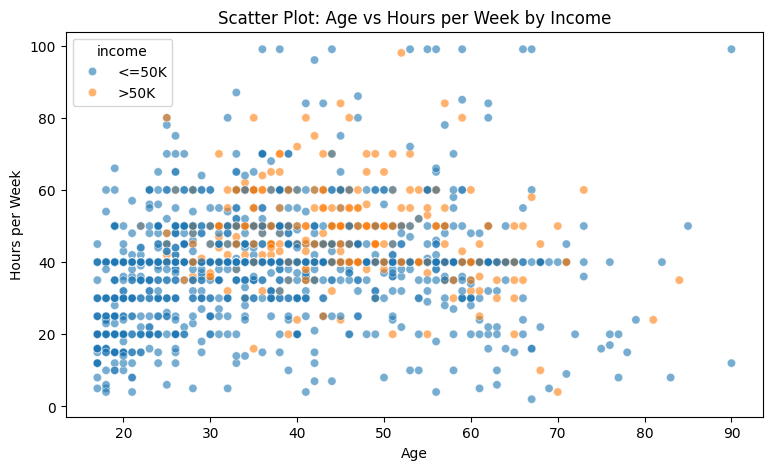

In [8]:
# Task 7: Scatter plot of age vs hours-per-week colored by income
# (Sample of 2000 points to make the plot clean and readable)
sample_df = df.sample(2000, random_state=42)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df, x='age', y='hours-per-week', hue='income', alpha=0.6)
plt.title('Scatter Plot: Age vs Hours per Week by Income')
plt.xlabel('Age')
plt.ylabel('Hours per Week')
plt.show()

**Answer & Interpretation:**
- **Relationship:**
  - There is a **weak, non-linear (inverted U-shaped) relationship**: younger individuals ($<25$) and older individuals ($>65$) work fewer hours, while middle-aged adults ($30-55$) consistently work 40+ hours per week.
- **Income (Color):**
  - High earners (`>50K`, orange) are concentrated in the middle-age group ($35-55$) working 40 or more hours per week.

---
## Task 8 : Line/Area Chart: Trend Across an Ordered Variable
> **Prompt:** Since none of these datasets has a true time column, choose an ordered variable instead (e.g., education-num for Adult) and plot the average of a numeric column across it as both a line chart and an area chart. Compare how the area fill changes the visual impression versus the plain line.

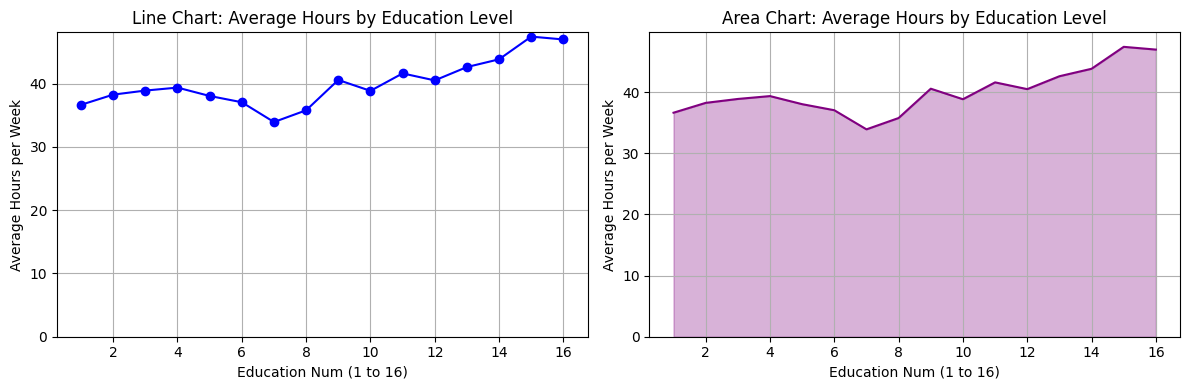

In [9]:
# Task 8: Line and Area chart across education-num
edu_trend = df.groupby('education-num')['hours-per-week'].mean().reset_index()

plt.figure(figsize=(12, 4))

# 1. Line Chart
plt.subplot(1, 2, 1)
plt.plot(edu_trend['education-num'], edu_trend['hours-per-week'], marker='o', color='blue')
plt.title('Line Chart: Average Hours by Education Level')
plt.xlabel('Education Num (1 to 16)')
plt.ylabel('Average Hours per Week')
plt.ylim(bottom=0)
plt.grid(True)

# 2. Area Chart
plt.subplot(1, 2, 2)
plt.plot(edu_trend['education-num'], edu_trend['hours-per-week'], color='purple')
plt.fill_between(edu_trend['education-num'], edu_trend['hours-per-week'], color='purple', alpha=0.3)
plt.title('Area Chart: Average Hours by Education Level')
plt.xlabel('Education Num (1 to 16)')
plt.ylabel('Average Hours per Week')
plt.ylim(bottom=0)
plt.grid(True)

plt.tight_layout()
plt.show()

**Comparison:**
- **Line Chart**: Focuses purely on the **rate and slope of change** from one education level to the next.
- **Area Chart**: Shading the area underneath emphasizes **accumulated volume and total magnitude**, which visually gives heavier optical weight to the data.
- **Visual Impression**: The area chart can make differences seem less dramatic because the large colored mass draws attention to the overall volume rather than small changes in slope.

---
## Task 9 : Graphical Integrity Check
> **Prompt:** Take your bar chart from Task 1 (or Task 2) and deliberately re-plot it with a y-axis that does not start at zero (`plt.ylim(bottom=X)` with some X above the minimum value). Compare the two versions side by side and write 2-3 sentences explaining how the truncated axis changes the impression of the data, even though the numbers haven't changed.

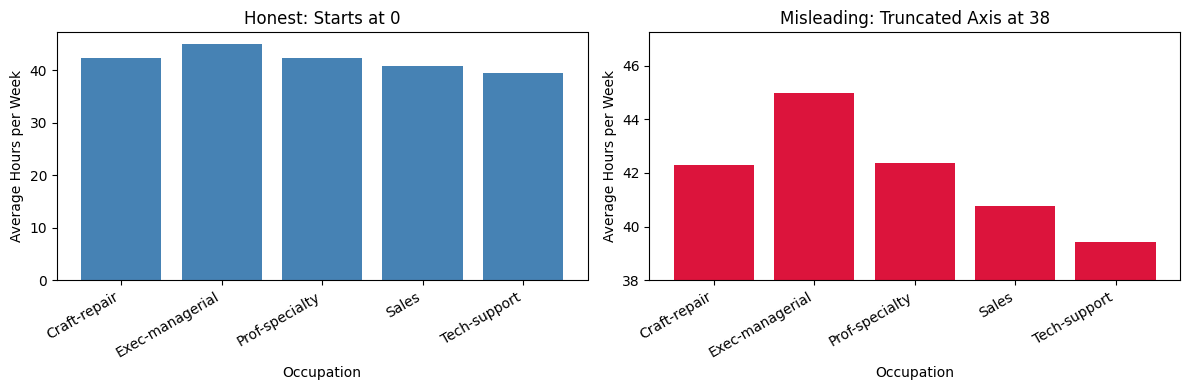

In [10]:
# Task 9: Side-by-side comparison of baseline at 0 vs truncated y-axis
# Select 5 occupations with close averages
selected = ['Exec-managerial', 'Prof-specialty', 'Craft-repair', 'Sales', 'Tech-support']
sub_df = avg_hours[avg_hours['occupation'].isin(selected)]

plt.figure(figsize=(12, 4))

# 1. Honest (Starts at 0)
plt.subplot(1, 2, 1)
plt.bar(sub_df['occupation'], sub_df['hours-per-week'], color='steelblue')
plt.title('Honest: Starts at 0')
plt.xlabel('Occupation')
plt.ylabel('Average Hours per Week')
plt.ylim(bottom=0)
plt.xticks(rotation=30, ha='right')

# 2. Misleading (Starts at 38)
plt.subplot(1, 2, 2)
plt.bar(sub_df['occupation'], sub_df['hours-per-week'], color='crimson')
plt.title('Misleading: Truncated Axis at 38')
plt.xlabel('Occupation')
plt.ylabel('Average Hours per Week')
plt.ylim(bottom=38)
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

**2–3 Sentences Explanation (Graphical Integrity):**
> 1. In the **Honest Chart**, the average hours worked across these five occupations look very similar (ranging narrowly between 39.4 and 45.0 hours, a small ~14% difference).
> 2. In the **Misleading Chart** with the truncated y-axis starting at 38, the bar for `Exec-managerial` visually looks **over four times taller** than `Tech-support`.
> 3. Truncating the axis distorts the visual length of the bars, creating a misleading impression and violating graphical integrity (*high Lie Factor*).

---
## Export Cleaned Dataset
Exporting the cleaned dataset `adult_cleaned_lab2.csv` for submission.

In [11]:
# Save cleaned dataset
df.to_csv('adult_cleaned_lab2.csv', index=False)
print("Cleaned dataset saved as 'adult_cleaned_lab2.csv'")

Cleaned dataset saved as 'adult_cleaned_lab2.csv'
